# Análise exploratória de redundância entre variáveis

Esta etapa investigará se algumas variáveis selecionadas representam informações muito semelhantes. A análise combinará gráficos e medidas de associação, sem excluir colunas automaticamente. Uma associação elevada poderá indicar sobreposição, mas a decisão de manter ou retirar uma variável dependerá também de seu significado e do objetivo do modelo.

Serão examinadas duas situações: a razão de renda em sua forma numérica e categórica; e as relações entre os itens das escalas GAD e PHQ, seus escores totais e suas categorias de severidade. As respostas codificadas como desconhecidas serão excluídas das medidas de associação.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

sns.set_theme(style="whitegrid", palette="deep")

arquivo_base = Path("../dados/dados_limpos") / "adult25_limpo.csv"
pasta_figuras = Path("figuras")
pasta_figuras.mkdir(exist_ok=True)

df = pd.read_csv(arquivo_base, low_memory=False)
print(f"Dimensões da base: {df.shape[0]:,} registros x {df.shape[1]} colunas")

Dimensões da base: 24,215 registros x 72 colunas


## Verificação de colunas exatamente iguais

Antes de avaliar associações estatísticas, será verificado se há pares de colunas com valores idênticos em todos os registros. Essa checagem identifica duplicidade exata de conteúdo; ela é diferente de uma correlação alta, que indica semelhança, mas não igualdade.

In [2]:
pares_iguais = []
colunas = list(df.columns)

for indice, coluna_a in enumerate(colunas):
    for coluna_b in colunas[indice + 1:]:
        if df[coluna_a].equals(df[coluna_b]):
            pares_iguais.append((coluna_a, coluna_b))

if pares_iguais:
    print("Pares de colunas exatamente iguais:")
    for coluna_a, coluna_b in pares_iguais:
        print(f"- {coluna_a} e {coluna_b}")
else:
    print("Nenhum par de colunas exatamente iguais foi encontrado.")

Nenhum par de colunas exatamente iguais foi encontrado.


## Razão de renda: valor numérico e categoria

A razão de renda e sua categoria correspondem a duas representações do mesmo conceito. O gráfico permitirá comparar a distribuição dos valores numéricos entre as faixas categóricas. A correlação de Spearman será usada por se tratar de uma associação monotônica entre uma medida numérica e categorias ordenadas. A categoria desconhecida (código 15), se presente, não participará da comparação.

Registros válidos: 24,215
Correlação de Spearman: 0.9816


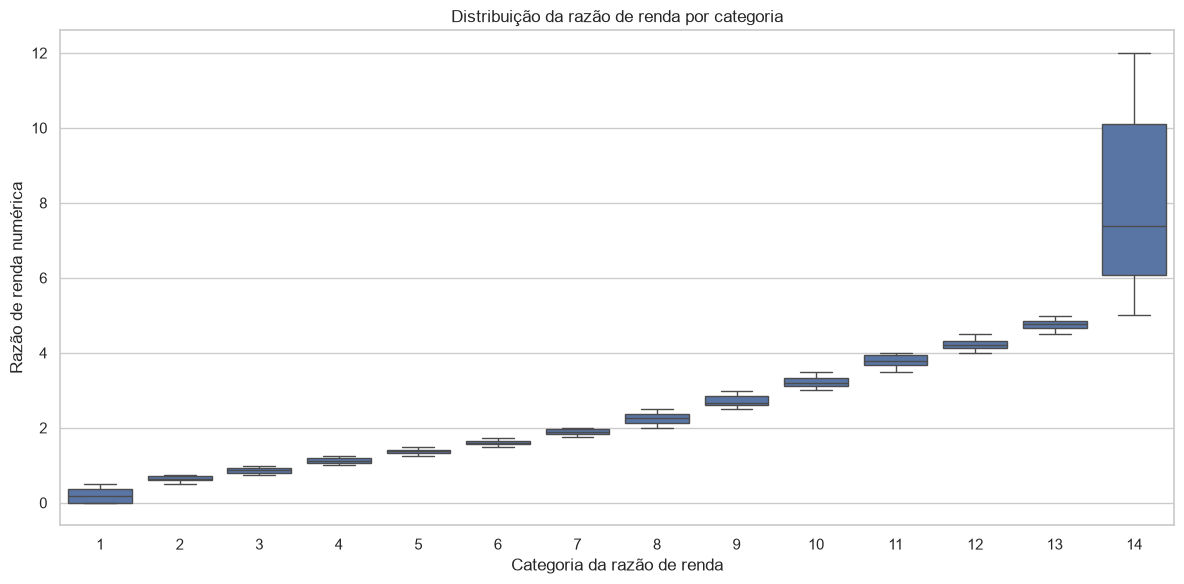

In [3]:
coluna_razao = "RAZAO_RENDA_POBREZA"
coluna_categoria = "CATEGORIA_RAZAO_POBREZA"
dados_renda = df[[coluna_razao, coluna_categoria]].copy()
dados_renda[coluna_razao] = pd.to_numeric(dados_renda[coluna_razao], errors="coerce")
dados_renda[coluna_categoria] = pd.to_numeric(dados_renda[coluna_categoria], errors="coerce")
dados_renda = dados_renda.dropna()
dados_renda = dados_renda[dados_renda[coluna_categoria].between(1, 14)]

rho_renda, _ = spearmanr(dados_renda[coluna_razao], dados_renda[coluna_categoria])
print(f"Registros válidos: {len(dados_renda):,}")
print(f"Correlação de Spearman: {rho_renda:.4f}")

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=dados_renda,
    x=coluna_categoria,
    y=coluna_razao,
    order=range(1, 15),
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Distribuição da razão de renda por categoria",
    xlabel="Categoria da razão de renda",
    ylabel="Razão de renda numérica",
)
fig.tight_layout()
fig.savefig(pasta_figuras / "01_razao_renda_categoria.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "01_razao_renda_categoria.pdf", bbox_inches="tight")
plt.show()

A correlação observada é muito alta (Spearman ρ ≈ 0,982), como esperado para duas representações da mesma medida. A categoria resume o valor em faixas e, portanto, perde parte do detalhe preservado pela variável numérica. As colunas são fortemente sobrepostas, mas não são cópias exatas; a escolha entre elas deverá considerar a necessidade de granularidade e a finalidade de cada análise.

## Escala de ansiedade (GAD)

A matriz de Spearman permitirá observar a associação entre os sete itens da escala e a categoria de severidade. Os itens válidos variam de 1 a 4; o código 5 representa resposta desconhecida e será convertido em ausente somente nesta análise. A categoria GAD também será tratada como ordinal, sem considerar o código desconhecido como uma severidade. Cada célula exibirá o coeficiente e o número de respostas válidas para aquele par de variáveis.

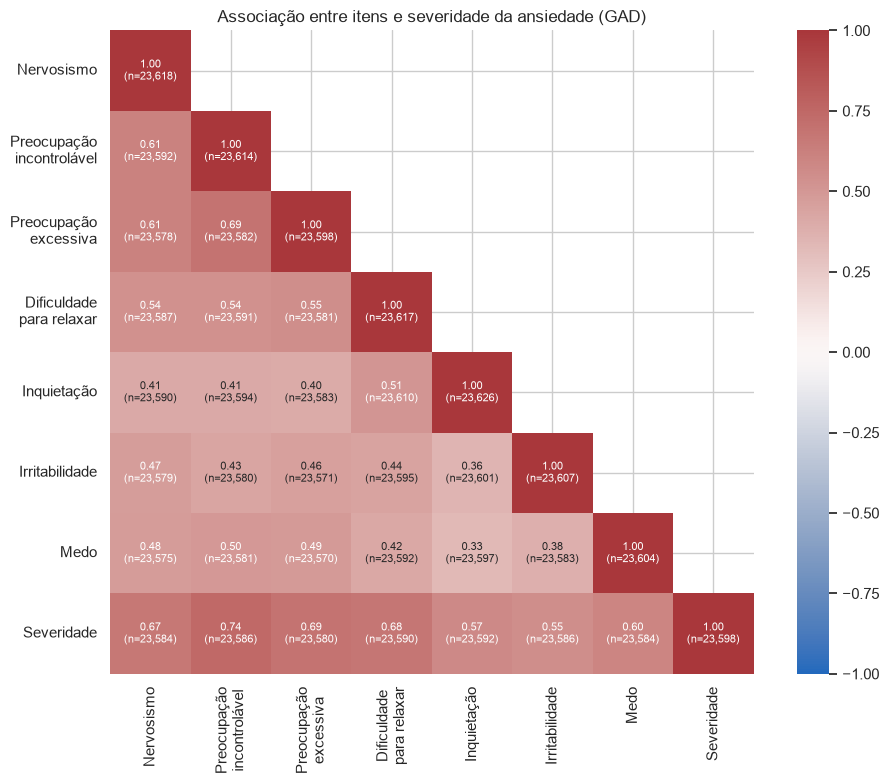

Maior associação entre itens GAD: ('FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM', 'FREQ_PREOCUPACAO_DESNECESSARIA_2SEM') (rho = 0.690)


In [4]:
itens_gad = [
    "FREQ_ANSIEDADE_2SEM",
    "FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM",
    "FREQ_PREOCUPACAO_DESNECESSARIA_2SEM",
    "FREQ_DIFICULDADE_DESCANSAR_2SEM",
    "FREQ_AGITACAO_INQUIETA",
    "FREQ_IRRITABILIDADE_2SEM",
    "FREQ_MEDO_2SEM",
]
coluna_gad = "SEVERIDADE_ANSIEDADE"
dados_gad = df[itens_gad + [coluna_gad]].apply(pd.to_numeric, errors="coerce")
dados_gad = dados_gad.where(dados_gad.le(4))
matriz_gad = dados_gad.corr(method="spearman", min_periods=2)
n_gad = dados_gad.notna().astype(int).T.dot(dados_gad.notna().astype(int))
nomes_gad = [
    "Nervosismo", "Preocupação\nincontrolável", "Preocupação\nexcessiva",
    "Dificuldade\npara relaxar", "Inquietação", "Irritabilidade", "Medo", "Severidade",
]
mapa_nomes_gad = dict(zip(itens_gad + [coluna_gad], nomes_gad))
matriz_gad_plot = matriz_gad.rename(index=mapa_nomes_gad, columns=mapa_nomes_gad)
anotacoes_gad = matriz_gad.copy().astype(object)
for linha in matriz_gad.index:
    for coluna in matriz_gad.columns:
        coeficiente = matriz_gad.loc[linha, coluna]
        n_par = n_gad.loc[linha, coluna]
        anotacoes_gad.loc[linha, coluna] = "" if pd.isna(coeficiente) else f"{coeficiente:.2f}\n(n={n_par:,})"
anotacoes_gad = anotacoes_gad.rename(index=mapa_nomes_gad, columns=mapa_nomes_gad)

fig, ax = plt.subplots(figsize=(10, 8))
mascara = np.triu(np.ones_like(matriz_gad, dtype=bool), k=1)
sns.heatmap(
    matriz_gad_plot,
    mask=mascara,
    annot=anotacoes_gad,
    fmt="",
    annot_kws={"size": 8},
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Associação entre itens e severidade da ansiedade (GAD)")
fig.tight_layout()
fig.savefig(pasta_figuras / "02_matriz_gad.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "02_matriz_gad.pdf", bbox_inches="tight")
plt.show()

pares_gad = matriz_gad.loc[itens_gad, itens_gad].where(
    np.triu(np.ones((len(itens_gad), len(itens_gad))), k=1).astype(bool)
).stack().sort_values(ascending=False)
print("Maior associação entre itens GAD:", pares_gad.index[0], f"(rho = {pares_gad.iloc[0]:.3f})")

### Escore dos itens e severidade GAD

Para comparar o escore total com a severidade, os códigos dos itens serão deslocados de 1–4 para 0–3. O escore será calculado apenas para participantes com resposta válida em todos os sete itens e na categoria de severidade. Assim, a comparação não misturará somas parciais com escores completos.

Respostas completas válidas: 23,514
Correlação escore-severidade: rho = 0.7043


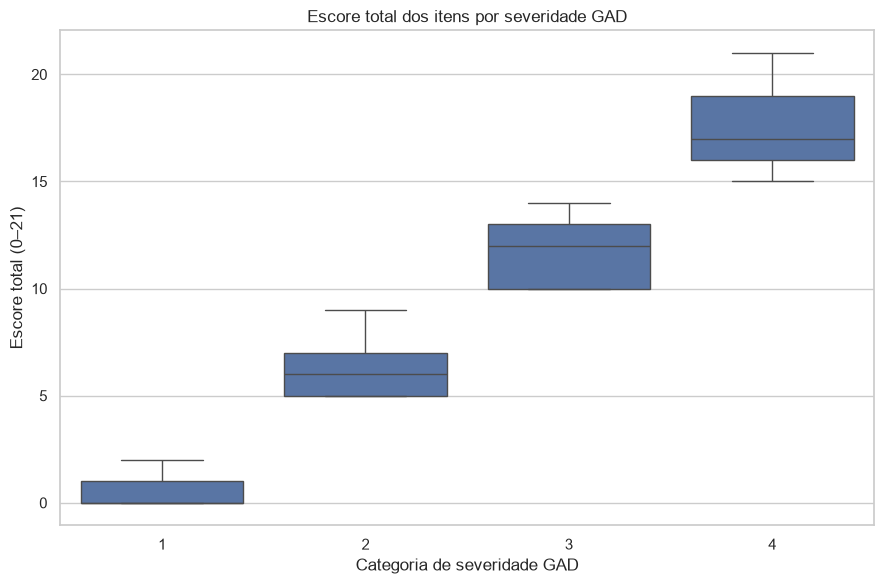

In [5]:
dados_score_gad = df[itens_gad + [coluna_gad]].apply(pd.to_numeric, errors="coerce")
validos_gad = dados_score_gad[itens_gad + [coluna_gad]].ge(1).all(axis=1) & dados_score_gad[itens_gad + [coluna_gad]].le(4).all(axis=1)
dados_score_gad = dados_score_gad.loc[validos_gad].copy()
dados_score_gad["ESCORE_GAD"] = dados_score_gad[itens_gad].sub(1).sum(axis=1)

rho_score_gad, _ = spearmanr(
    dados_score_gad["ESCORE_GAD"], dados_score_gad[coluna_gad]
)
print(f"Respostas completas válidas: {len(dados_score_gad):,}")
print(f"Correlação escore-severidade: rho = {rho_score_gad:.4f}")

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=dados_score_gad,
    x=coluna_gad,
    y="ESCORE_GAD",
    order=[1, 2, 3, 4],
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Escore total dos itens por severidade GAD",
    xlabel="Categoria de severidade GAD",
    ylabel="Escore total (0–21)",
)
fig.tight_layout()
fig.savefig(pasta_figuras / "03_escore_gad_severidade.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "03_escore_gad_severidade.pdf", bbox_inches="tight")
plt.show()

## Escala de depressão (PHQ)

A mesma análise será aplicada aos oito itens da escala PHQ e à categoria de severidade correspondente. As respostas válidas dos itens variam de 1 a 4; o código 5 (desconhecido) será excluído. A matriz permitirá avaliar a relação entre itens e identificar se algum par apresenta associação particularmente elevada. Cada célula exibirá o coeficiente e o número de respostas válidas para aquele par.

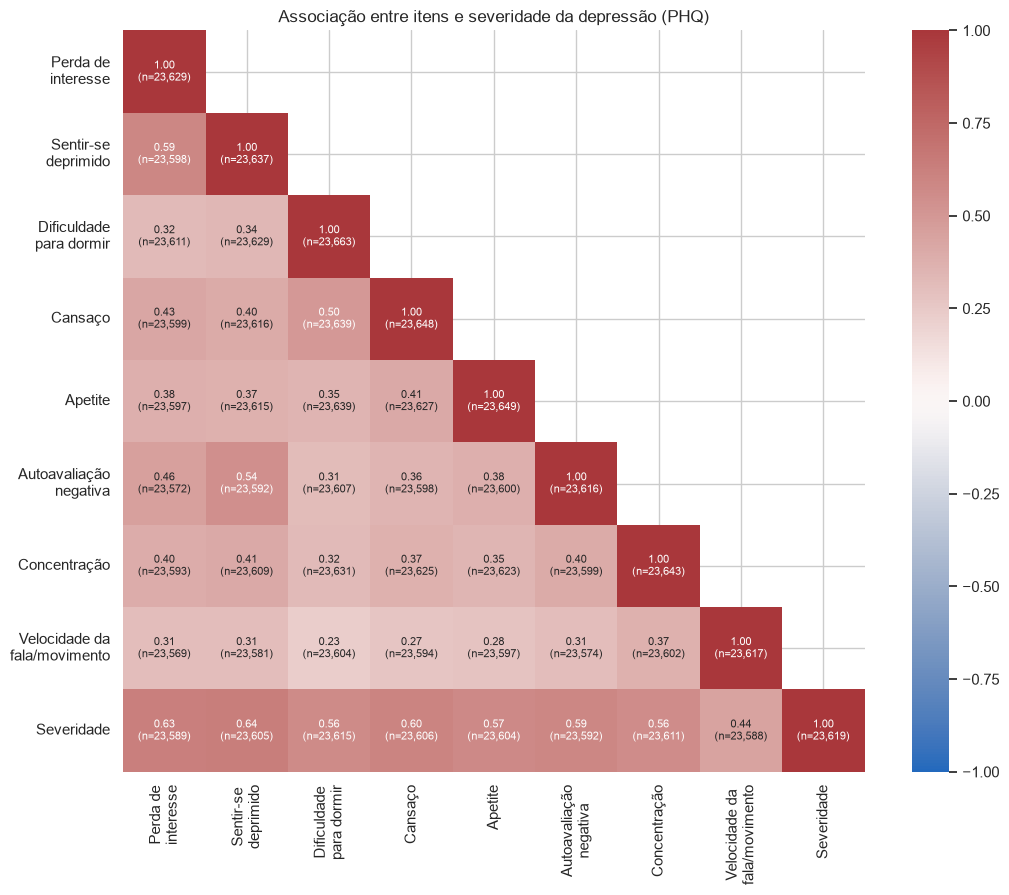

Maior associação entre itens PHQ: ('FREQ_PERDA_INTERESSE_2SEM', 'FREQ_SENTIU_DEPRIMIDO_2SEM') (rho = 0.592)


In [6]:
itens_phq = [
    "FREQ_PERDA_INTERESSE_2SEM",
    "FREQ_SENTIU_DEPRIMIDO_2SEM",
    "FREQ_DIFICULDADE_DORMIR_2SEM",
    "FREQ_CANSASO_2SEM",
    "FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM",
    "FREQ_AUTOAVALIACAO_NEGTIVA_2SEM",
    "FREQ_DIFICULDADE_CONCENTRACAO_2SEM",
    "MODIFICACAO_VELOCIDADE_FALA",
]
coluna_phq = "SEVERIDADE_DEPRESSAO_PHQ"
dados_phq = df[itens_phq + [coluna_phq]].apply(pd.to_numeric, errors="coerce")
dados_phq = dados_phq.where(dados_phq.le(4))
matriz_phq = dados_phq.corr(method="spearman", min_periods=2)
n_phq = dados_phq.notna().astype(int).T.dot(dados_phq.notna().astype(int))
nomes_phq = [
    "Perda de\ninteresse", "Sentir-se\ndeprimido", "Dificuldade\npara dormir",
    "Cansaço", "Apetite", "Autoavaliação\nnegativa", "Concentração",
    "Velocidade da\nfala/movimento", "Severidade",
]
mapa_nomes_phq = dict(zip(itens_phq + [coluna_phq], nomes_phq))
matriz_phq_plot = matriz_phq.rename(index=mapa_nomes_phq, columns=mapa_nomes_phq)
anotacoes_phq = matriz_phq.copy().astype(object)
for linha in matriz_phq.index:
    for coluna in matriz_phq.columns:
        coeficiente = matriz_phq.loc[linha, coluna]
        n_par = n_phq.loc[linha, coluna]
        anotacoes_phq.loc[linha, coluna] = "" if pd.isna(coeficiente) else f"{coeficiente:.2f}\n(n={n_par:,})"
anotacoes_phq = anotacoes_phq.rename(index=mapa_nomes_phq, columns=mapa_nomes_phq)

fig, ax = plt.subplots(figsize=(11, 9))
mascara = np.triu(np.ones_like(matriz_phq, dtype=bool), k=1)
sns.heatmap(
    matriz_phq_plot,
    mask=mascara,
    annot=anotacoes_phq,
    fmt="",
    annot_kws={"size": 8},
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title("Associação entre itens e severidade da depressão (PHQ)")
fig.tight_layout()
fig.savefig(pasta_figuras / "04_matriz_phq.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "04_matriz_phq.pdf", bbox_inches="tight")
plt.show()

pares_phq = matriz_phq.loc[itens_phq, itens_phq].where(
    np.triu(np.ones((len(itens_phq), len(itens_phq))), k=1).astype(bool)
).stack().sort_values(ascending=False)
print("Maior associação entre itens PHQ:", pares_phq.index[0], f"(rho = {pares_phq.iloc[0]:.3f})")

### Escore dos itens e severidade PHQ

O escore dos oito itens será convertido para a escala de 0 a 24 e calculado somente quando todos os itens e a categoria de severidade tiverem respostas válidas. O boxplot mostrará a distribuição do escore em cada nível da categoria.

Respostas completas válidas: 23,477
Correlação escore-severidade: rho = 0.7320


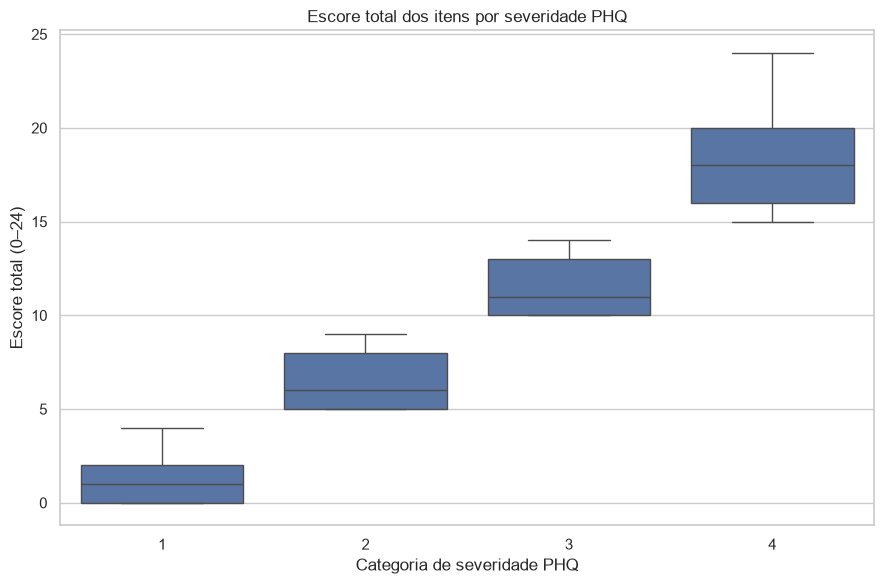

In [7]:
dados_score_phq = df[itens_phq + [coluna_phq]].apply(pd.to_numeric, errors="coerce")
validos_phq = dados_score_phq[itens_phq + [coluna_phq]].ge(1).all(axis=1) & dados_score_phq[itens_phq + [coluna_phq]].le(4).all(axis=1)
dados_score_phq = dados_score_phq.loc[validos_phq].copy()
dados_score_phq["ESCORE_PHQ"] = dados_score_phq[itens_phq].sub(1).sum(axis=1)

rho_score_phq, _ = spearmanr(
    dados_score_phq["ESCORE_PHQ"], dados_score_phq[coluna_phq]
)
print(f"Respostas completas válidas: {len(dados_score_phq):,}")
print(f"Correlação escore-severidade: rho = {rho_score_phq:.4f}")

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=dados_score_phq,
    x=coluna_phq,
    y="ESCORE_PHQ",
    order=[1, 2, 3, 4],
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Escore total dos itens por severidade PHQ",
    xlabel="Categoria de severidade PHQ",
    ylabel="Escore total (0–24)",
)
fig.tight_layout()
fig.savefig(pasta_figuras / "05_escore_phq_severidade.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "05_escore_phq_severidade.pdf", bbox_inches="tight")
plt.show()

## Relação entre as severidades GAD e PHQ

Como última comparação, será exibido o percentual da categoria PHQ dentro de cada categoria GAD. A associação entre elas indica que os construtos podem estar relacionados, mas não será interpretada como redundância: ansiedade e depressão são dimensões distintas, ainda que possam coexistir.

Registros válidos: 23,571
Correlação de Spearman: rho = 0.6157


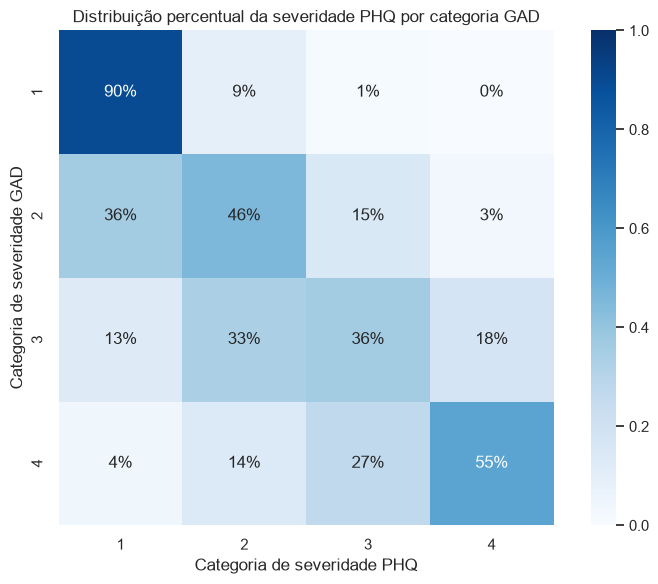

In [8]:
dados_severidades = df[[coluna_gad, coluna_phq]].apply(pd.to_numeric, errors="coerce")
dados_severidades = dados_severidades.where(dados_severidades.le(4)).dropna()
tabela_severidades = pd.crosstab(
    dados_severidades[coluna_gad],
    dados_severidades[coluna_phq],
    normalize="index",
).reindex(index=[1, 2, 3, 4], columns=[1, 2, 3, 4])
rho_severidades, _ = spearmanr(
    dados_severidades[coluna_gad], dados_severidades[coluna_phq]
)
print(f"Registros válidos: {len(dados_severidades):,}")
print(f"Correlação de Spearman: rho = {rho_severidades:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    tabela_severidades,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set(
    title="Distribuição percentual da severidade PHQ por categoria GAD",
    xlabel="Categoria de severidade PHQ",
    ylabel="Categoria de severidade GAD",
)
fig.tight_layout()
fig.savefig(pasta_figuras / "06_severidades_gad_phq.png", dpi=150, bbox_inches="tight")
fig.savefig(pasta_figuras / "06_severidades_gad_phq.pdf", bbox_inches="tight")
plt.show()

## Síntese da análise

- **Razão de renda:** a variável numérica e sua categoria apresentam associação muito alta (ρ ≈ 0,982), pois descrevem o mesmo conceito em níveis diferentes de detalhe. Esse é o principal caso de sobreposição identificado; a versão categórica resume a informação numérica.
- **Itens GAD e PHQ:** a maior associação entre itens GAD foi observada entre preocupação incontrolável e preocupação excessiva (rho ≈ 0,690); entre itens PHQ, entre perda de interesse e sentir-se deprimido (rho ≈ 0,592). As associações apontam itens relacionados, não cópias exatas.
- **Escore e severidade:** houve associação entre os escores completos e suas categorias de severidade (GAD: rho ≈ 0,704; PHQ: rho ≈ 0,732). As categorias são variáveis derivadas com utilidades analíticas distintas dos escores e dos itens.
- **GAD e PHQ:** a associação entre as duas severidades (ρ ≈ 0,616) indica relação entre os construtos, não equivalência nem redundância automática.

As associações serão usadas como evidência para documentar a sobreposição, não como regra automática de exclusão. Para análises futuras, a razão numérica e a categoria poderão ser avaliadas como alternativas, enquanto itens, escores e severidades serão mantidos no conjunto de trabalho para permitir diferentes objetivos analíticos. Qualquer exclusão para um modelo específico será registrada separadamente e definida de acordo com a tarefa, evitando retirar informação apenas com base em um coeficiente.